# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman tentang Simple Regression dan Simple Classification.

**Identitas Mahasiswa**
- Nama  : Satria Anggara
- NIM   : 241011400322
- Kelas : Reg C


## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [ ]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 22


In [ ]:
# Implementasi train_test_split menggunakan NumPy

def train_test_split(X, y, test_size=0.2, random_state=22):
    X = np.asarray(X)
    y = np.asarray(y)
    if len(X) != len(y):
        raise ValueError("X dan y harus memiliki jumlah baris yang sama")
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

class LinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_bias = np.c_[np.ones((X.shape[0], 1)), X]
        theta = np.linalg.pinv(X_bias.T @ X_bias) @ X_bias.T @ y
        self.intercept_ = float(theta[0, 0])
        self.coef_ = theta[1:, 0]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_

class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_bias = np.c_[np.ones((len(X), 1)), X]
        theta = np.zeros(X_bias.shape[1])
        for _ in range(self.n_iterations):
            error = X_bias @ theta - y
            theta -= self.learning_rate * (2 / len(y)) * (X_bias.T @ error)
            with np.errstate(over='ignore', invalid='ignore'):
                self.loss_history.append(float(np.mean((X_bias @ theta - y) ** 2)))
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        X_bias = np.c_[np.ones((len(X), 1)), X]
        return self.sigmoid(X_bias @ self.theta_)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        X_bias = np.c_[np.ones((len(X), 1)), X]
        self.theta_ = np.zeros((X_bias.shape[1], 1))
        for _ in range(self.n_iterations):
            p = self.sigmoid(X_bias @ self.theta_)
            grad = X_bias.T @ (p - y) / len(y)
            self.theta_ -= self.learning_rate * grad
            p = np.clip(self.sigmoid(X_bias @ self.theta_), 1e-12, 1 - 1e-12)
            loss = -np.mean(y * np.log(p) + (1-y) * np.log(1-p))
            self.loss_history.append(float(loss))
        self.intercept_ = float(self.theta_[0, 0])
        self.coef_ = self.theta_[1:, 0]
        return self

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X).ravel() >= threshold).astype(int)

def accuracy_score(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    return np.array([[np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
                     [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))]])


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


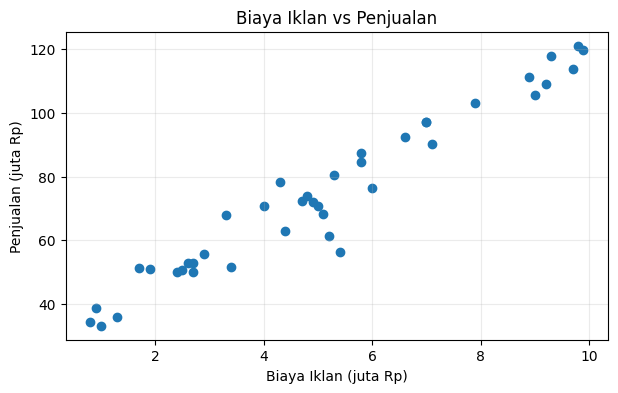

In [ ]:
# Jawaban A1
ads = pd.read_csv("Ads_Data.csv")
display(ads.head())
print("Jumlah baris data:", len(ads))
X = ads[["BiayaIklan"]].to_numpy(dtype=float)  # bentuk (n, 1)
y = ads["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], y)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.25)
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
# Jawaban A3
lin_reg = LinearRegression().fit(X_train, y_train)
print(f"Intercept (b): {lin_reg.intercept_:.4f}")
print(f"Koefisien (m): {lin_reg.coef_[0]:.4f}")
print(f"Persamaan regresi: ŷ = {lin_reg.intercept_:.4f} + ({lin_reg.coef_[0]:.4f})X")


Intercept (b): 28.4919
Koefisien (m): 9.0986
Persamaan regresi: ŷ = 28.4919 + (9.0986)X


**Jawaban A3 (interpretasi):**

Koefisien yang diperoleh sekitar **9,0986**. Artinya, pada model ini setiap kenaikan biaya iklan sebesar Rp1 juta berkaitan dengan kenaikan prediksi penjualan sekitar Rp9,10 juta. Ini adalah hubungan yang dipelajari dari data, bukan bukti bahwa iklan menjadi satu-satunya penyebab kenaikan penjualan.


### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
# Jawaban A4

def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan
    return mae, mse, rmse, r2

pred_train = lin_reg.predict(X_train)
pred_test = lin_reg.predict(X_test)
metrics_train = regression_metrics(y_train, pred_train)
metrics_test = regression_metrics(y_test, pred_test)
metrics_table = pd.DataFrame([metrics_train, metrics_test], index=["Training", "Testing"], columns=["MAE", "MSE", "RMSE", "R²"])
display(metrics_table.round(4))


,MAE,MSE,RMSE,R²
Training,4.2300,32.9379,5.7392,0.9415
Testing,5.5414,48.6240,6.9731,0.9431


**Jawaban A4 (analisis):**

Dari tabel, RMSE training sekitar **5,7392** dan RMSE testing sekitar **6,9731 juta rupiah**, sehingga besar kesalahan prediksi testing rata-rata berada di kisaran 6,97 juta rupiah menurut ukuran RMSE. Nilai **R² testing = 0,9431** berarti model menjelaskan sekitar 94,31% variasi penjualan pada data testing. Hasil ini menunjukkan hubungan linear yang cukup kuat pada dataset ini, meskipun kesalahan prediksi masih ada dan hasil tidak menjamin performa yang sama pada kondisi bisnis lain.


### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

/tmp/ipykernel_651/267514031.py:42: RuntimeWarning: overflow encountered in matmul
  theta -= self.learning_rate * (2 / len(y)) * (X_bias.T @ error)
/tmp/ipykernel_651/267514031.py:42: RuntimeWarning: invalid value encountered in subtract
  theta -= self.learning_rate * (2 / len(y)) * (X_bias.T @ error)


,Learning rate,Intercept,Koefisien,MSE akhir,Finite loss
0,0.001,25.25967,9.62709,35.18621,True
1,0.020,28.49189,9.09864,32.93793,True
2,0.100,NaN,NaN,NaN,False


Normal Equation: intercept=28.4919, koefisien=9.0986


/opt/pyvenv/lib/python3.13/site-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


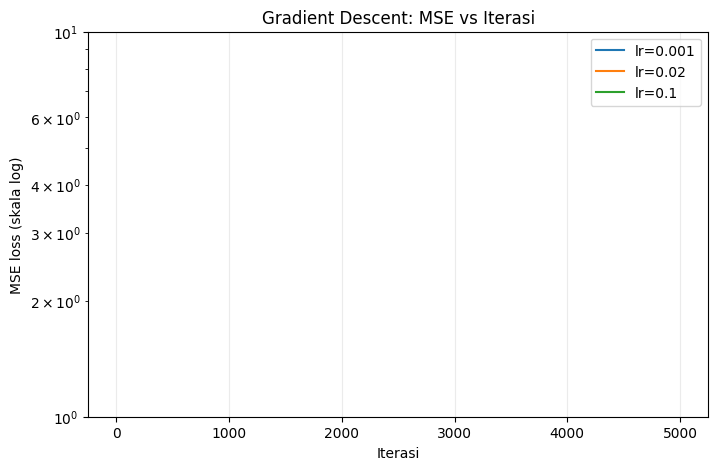

In [ ]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
rows = []
for lr in learning_rates:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    rows.append({"Learning rate": lr, "Intercept": model.intercept_, "Koefisien": model.coef_[0],
                 "MSE akhir": model.loss_history[-1], "Finite loss": np.isfinite(model.loss_history[-1])})
display(pd.DataFrame(rows).round(5))
print(f"Normal Equation: intercept={lin_reg.intercept_:.4f}, koefisien={lin_reg.coef_[0]:.4f}")

plt.figure(figsize=(8, 5))
for lr, model in gd_models.items():
    losses = np.asarray(model.loss_history)
    plt.plot(np.arange(1, len(losses)+1), losses, label=f"lr={lr}")
plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("MSE loss (skala log)")
plt.title("Gradient Descent: MSE vs Iterasi")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


**Jawaban A5 (analisis):**

Pada learning rate **0,001**, loss akhir sekitar **35,1862** dan koefisiennya masih agak berbeda dari Normal Equation, sehingga pembelajarannya lebih lambat. Learning rate **0,02** mencapai loss sekitar **32,9379** dan parameter mendekati Normal Equation (intercept 28,4919 dan koefisien 9,0986), sehingga paling sesuai di antara tiga percobaan ini. Pada learning rate **0,1**, parameter dan loss menjadi `NaN` setelah nilai membesar, menandakan langkah pembaruan terlalu besar dan proses divergen. Peringatan overflow muncul karena perhitungan kuadrat error atau perkalian matriks membesar melewati batas representasi numerik.


### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

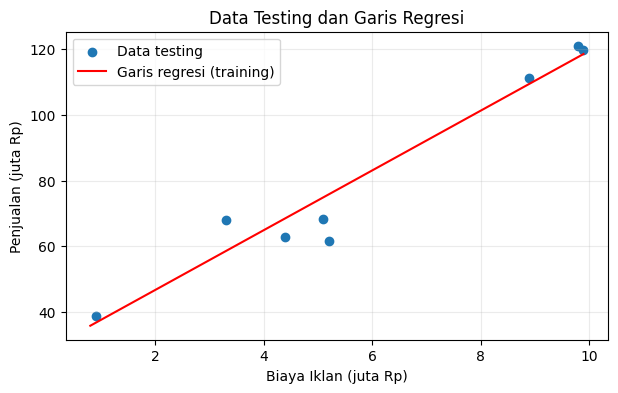

,BiayaIklan (juta Rp),PrediksiPenjualan (juta Rp)
0,4.5,69.436
1,7.0,92.182
2,12.0,137.676


In [ ]:
# Jawaban A6
plt.figure(figsize=(7, 4))
plt.scatter(X_test[:, 0], y_test, label="Data testing")
x_line = np.linspace(float(X.min()), float(X.max()), 200).reshape(-1, 1)
plt.plot(x_line[:, 0], lin_reg.predict(x_line), color="red", label="Garis regresi (training)")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_baru = lin_reg.predict(biaya_baru)
display(pd.DataFrame({"BiayaIklan (juta Rp)": biaya_baru.ravel(), "PrediksiPenjualan (juta Rp)": prediksi_baru}).round(3))


**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan 4,5 juta dan 7 juta berada di dalam rentang biaya iklan pada dataset sehingga lebih dekat dengan interpolasi. Prediksi untuk 12 juta berada di luar rentang pengamatan (ekstrapolasi). Hasil ekstrapolasi perlu lebih hati-hati karena hubungan antara biaya iklan dan penjualan belum tentu tetap linear di luar data yang tersedia, dan faktor lain seperti musim, harga, serta kondisi pasar tidak dimasukkan ke model.


---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email per kelas (0=bukan spam, 1=spam):
Spam
Bukan Spam    35
Spam          25
Name: count, dtype: int64


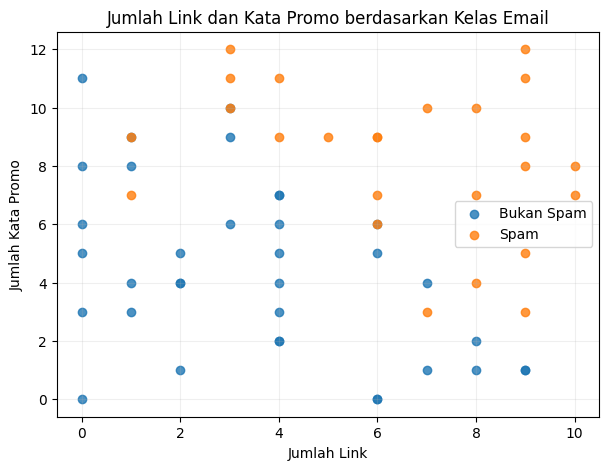

In [ ]:
# Jawaban B1
email = pd.read_csv("Email_Data.csv")
display(email.head())
print("Jumlah email per kelas (0=bukan spam, 1=spam):")
print(email["Spam"].value_counts().sort_index().rename(index={0: "Bukan Spam", 1: "Spam"}))
X_email = email[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = email["Spam"].to_numpy(dtype=int)

plt.figure(figsize=(7, 5))
for label, name, color in [(0, "Bukan Spam", "tab:blue"), (1, "Spam", "tab:orange")]:
    mask = y_email == label
    plt.scatter(X_email[mask, 0], X_email[mask, 1], label=name, alpha=0.8, color=color)
plt.title("Jumlah Link dan Kata Promo berdasarkan Kelas Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) X_test: (15, 2)
Intercept (b): -8.79222
Koefisien (m1, m2): [0.75694 0.76365]
P(Spam) = sigmoid(-8.79222 + (0.75694)*JumlahLink + (0.76365)*KataPromo)


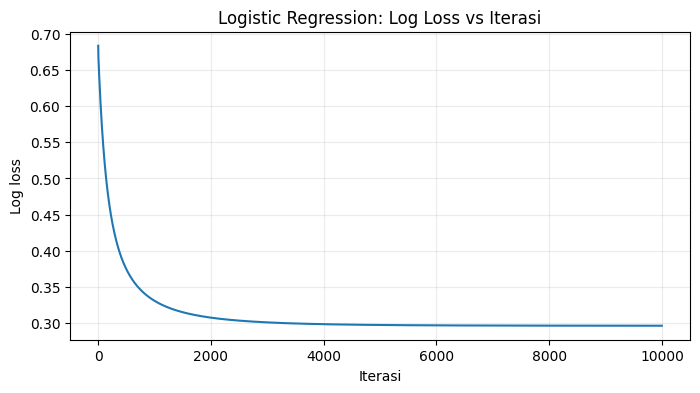

In [ ]:
# Jawaban B2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)
log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_email, y_train_email)
print("X_train:", X_train_email.shape, "X_test:", X_test_email.shape)
print("Intercept (b):", round(log_reg.intercept_, 5))
print("Koefisien (m1, m2):", np.round(log_reg.coef_, 5))
print(f"P(Spam) = sigmoid({log_reg.intercept_:.5f} + ({log_reg.coef_[0]:.5f})*JumlahLink + ({log_reg.coef_[1]:.5f})*KataPromo)")

plt.figure(figsize=(8, 4))
plt.plot(log_reg.loss_history)
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.title("Logistic Regression: Log Loss vs Iterasi")
plt.grid(alpha=0.25)
plt.show()


**Jawaban B2 (analisis):**

Model menghasilkan intercept sekitar **-8,7922** dan koefisien positif sekitar **0,7569** untuk jumlah link serta **0,7637** untuk kata promo. Dengan fitur lain tetap, kenaikan salah satu fitur meningkatkan skor linear dan probabilitas spam. Kurva log loss turun dari sekitar 0,693 pada awal pelatihan menjadi sekitar **0,296** di akhir 10.000 iterasi. Ini menunjukkan model belajar; loss yang terus turun perlahan di akhir menandakan proses optimisasi mendekati stabil.


### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [ ]:
# Jawaban B3

def classification_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {"Accuracy": accuracy_score(y_true, y_pred), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Precision": precision, "Recall": recall, "F1": f1}

pred_test_email = log_reg.predict(X_test_email)
cm_test = confusion_matrix(y_test_email, pred_test_email)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm_test)
result_b3 = classification_metrics(y_test_email, pred_test_email)
display(pd.DataFrame([result_b3]).round(4))


Confusion matrix [[TN, FP], [FN, TP]]:
[[9 1]
 [0 5]]


,Accuracy,TN,FP,FN,TP,Precision,Recall,F1
0,0.9333,9,1,0,5,0.8333,1.0,0.9091


**Jawaban B3 (analisis):**

Confusion matrix testing adalah `[[9, 1], [0, 5]]`, sehingga terdapat 9 true negative, 1 false positive, 0 false negative, dan 5 true positive. Accuracy sebesar **0,9333**, precision **0,8333**, recall **1,0**, dan F1 **0,9091**. FP berarti email bukan spam keliru masuk kategori spam, sedangkan FN berarti spam lolos ke kotak masuk. Pada hasil ini tidak ada FN, tetapi ada satu FP; saya akan tetap memantau FP karena email penting yang tertahan bisa merugikan pengguna.


### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: -8.79222 + (0.75694)*JumlahLink + (0.76365)*KataPromo = 0


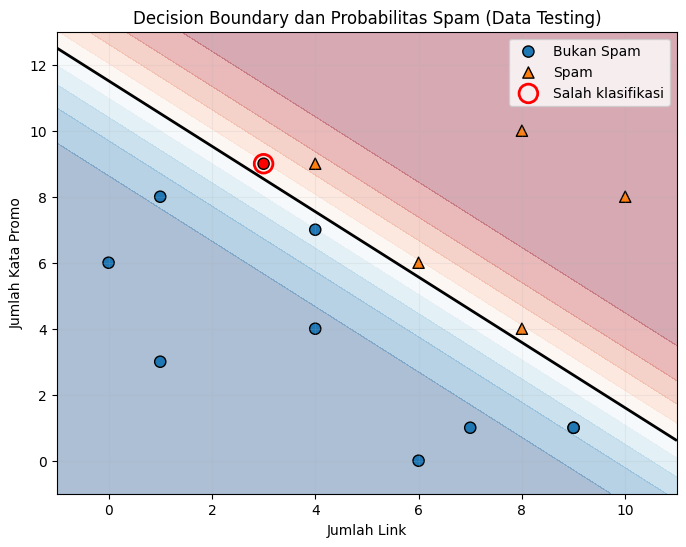

Data testing yang salah diklasifikasikan:


,JumlahLink,KataPromo,Aktual,Prediksi
0,3.0,9.0,0,1


In [ ]:
# Jawaban B4
b = log_reg.intercept_
m1, m2 = log_reg.coef_
print(f"Decision boundary: {b:.5f} + ({m1:.5f})*JumlahLink + ({m2:.5f})*KataPromo = 0")

x1_min, x1_max = X_email[:, 0].min()-1, X_email[:, 0].max()+1
x2_min, x2_max = X_email[:, 1].min()-1, X_email[:, 1].max()+1
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, 250), np.linspace(x2_min, x2_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]
prob_grid = log_reg.predict_proba(grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, prob_grid, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.35)
plt.contour(xx, yy, prob_grid, levels=[0.5], colors="black", linewidths=2)
for label, name, marker in [(0, "Bukan Spam", "o"), (1, "Spam", "^")]:
    mask = y_test_email == label
    plt.scatter(X_test_email[mask, 0], X_test_email[mask, 1], c=np.where(pred_test_email[mask] == label, "tab:blue" if label == 0 else "tab:orange", "red"), marker=marker, edgecolors="black", label=name, s=65)
wrong = pred_test_email != y_test_email
if np.any(wrong):
    plt.scatter(X_test_email[wrong, 0], X_test_email[wrong, 1], facecolors="none", edgecolors="red", s=180, linewidths=2, label="Salah klasifikasi")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.title("Decision Boundary dan Probabilitas Spam (Data Testing)")
plt.legend()
plt.grid(alpha=0.15)
plt.show()

misclassified = pd.DataFrame(X_test_email[wrong], columns=["JumlahLink", "KataPromo"])
misclassified["Aktual"] = y_test_email[wrong]
misclassified["Prediksi"] = pred_test_email[wrong]
print("Data testing yang salah diklasifikasikan:")
display(misclassified.reset_index(drop=True))


**Jawaban B4 (analisis):**

Decision boundary adalah garis dengan probabilitas prediksi 0,5. Titik di sisi dengan probabilitas di atas 0,5 diprediksi sebagai spam, sedangkan titik di sisi lainnya diprediksi bukan spam. Pada grafik, titik yang dilingkari merah merupakan data testing yang prediksinya tidak sama dengan label aktual. Kesalahan dapat terjadi karena kedua fitur saja belum sepenuhnya memisahkan kelas spam dan bukan spam.


### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [ ]:
# Jawaban B5
threshold_rows = []
p_test = log_reg.predict_proba(X_test_email).ravel()
for threshold in [0.3, 0.5, 0.7]:
    pred = (p_test >= threshold).astype(int)
    cm = confusion_matrix(y_test_email, pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    threshold_rows.append({"Threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                           "Precision": precision, "Recall": recall})
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))
# Threshold 0.5 memberi recall 1.0 dengan FP lebih sedikit dibanding threshold 0.3 pada data testing ini.
THRESHOLD_PILIHAN = 0.5
print("Threshold pilihan untuk prediksi email baru:", THRESHOLD_PILIHAN)


,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,8,2,0,5,0.7143,1.0
1,0.5,9,1,0,5,0.8333,1.0
2,0.7,10,0,2,3,1.0000,0.6


Threshold pilihan untuk prediksi email baru: 0.5


**Jawaban B5 (analisis):**

Pada threshold **0,3**, precision 0,7143 dan recall 1,0; pada threshold **0,5**, precision naik menjadi 0,8333 dan recall tetap 1,0. Pada threshold **0,7**, precision menjadi 1,0 tetapi recall turun menjadi 0,6, sehingga dua email spam pada data testing tidak terdeteksi. Berdasarkan hasil ini saya memilih threshold **0,5**, karena dibanding 0,3, recall tetap sempurna dengan false positive lebih sedikit, sedangkan threshold 0,7 melewatkan lebih banyak spam.


### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [ ]:
# Jawaban B6
new_emails = pd.DataFrame({"Email": ["E1", "E2", "E3", "E4"],
                           "JumlahLink": [1, 5, 9, 2], "KataPromo": [2, 6, 10, 11]})
X_new = new_emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
new_prob = log_reg.predict_proba(X_new).ravel()
new_pred = (new_prob >= THRESHOLD_PILIHAN).astype(int)
new_emails["Probabilitas Spam"] = new_prob
new_emails["Prediksi"] = np.where(new_pred == 1, "Spam", "Bukan Spam")
display(new_emails.round(4))


,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi
0,E1,1,2,0.0015,Bukan Spam
1,E2,5,6,0.3952,Bukan Spam
2,E3,9,10,0.9965,Spam
3,E4,2,11,0.7543,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk klasifikasi karena digunakan untuk memperkirakan probabilitas suatu data termasuk ke dalam kelas tertentu, misalnya spam atau bukan spam. Fungsi sigmoid mengubah skor linear menjadi nilai antara 0 dan 1. Nilai probabilitas tersebut kemudian dibandingkan dengan threshold untuk menentukan kelas prediksi.

**Jawaban C2:** Normal equation menghitung parameter secara langsung melalui operasi matriks, sehingga tidak memerlukan proses iterasi. Gradient descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss. Gradient descent lebih sesuai untuk dataset besar atau banyak fitur ketika penyelesaian matriks langsung mahal, tetapi learning rate harus dipilih dengan tepat.

**Jawaban C3:** Data testing dipakai untuk menilai kemampuan model pada data yang tidak digunakan saat pelatihan. Jika hanya mengevaluasi data training, hasilnya dapat terlihat terlalu bagus karena model sudah menyesuaikan diri dengan data tersebut. Overfitting terjadi ketika model terlalu mengikuti pola atau noise pada data training sehingga kinerjanya menurun pada data baru.

**Jawaban C4:** Linear Regression menghasilkan nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih antara nilai aktual dan prediksi. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss menilai seberapa tepat probabilitas yang diberikan terhadap label sebenarnya. Log loss memberi penalti besar ketika model memberikan probabilitas yang sangat yakin tetapi salah.

**Jawaban C5:** Hasil dapat berbeda karena pembagian training dan testing dipengaruhi oleh `random_state`. Perbedaan juga dapat muncul dari inisialisasi parameter, learning rate, jumlah iterasi, preprocessing, atau cara implementasi algoritma. Dalam tugas ini `random_state=22` digunakan agar pembagian data dapat direproduksi.


---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
# Jawaban Bonus
try:
    from sklearn.linear_model import LinearRegression as SklearnLinearRegression
    from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

    sk_lin = SklearnLinearRegression().fit(X_train, y_train)
    print("Linear Regression - implementasi sendiri vs scikit-learn")
    display(pd.DataFrame({"Parameter": ["Intercept", "Koefisien"],
                          "NumPy": [lin_reg.intercept_, lin_reg.coef_[0]],
                          "scikit-learn": [sk_lin.intercept_, sk_lin.coef_[0]]}).round(5))
    print("R² testing NumPy:", round(regression_metrics(y_test, lin_reg.predict(X_test))[3], 5))
    print("R² testing sklearn:", round(sk_lin.score(X_test, y_test), 5))

    sk_log = SklearnLogisticRegression(max_iter=10000, C=1e6, solver="lbfgs")
    sk_log.fit(X_train_email, y_train_email)
    sk_pred = sk_log.predict(X_test_email)
    print("\nLogistic Regression - implementasi sendiri vs scikit-learn")
    display(pd.DataFrame({"Parameter": ["Intercept", "Koefisien JumlahLink", "Koefisien KataPromo"],
                          "NumPy": [log_reg.intercept_, *log_reg.coef_],
                          "scikit-learn": [sk_log.intercept_[0], *sk_log.coef_[0]]}).round(5))
    print("Accuracy testing NumPy:", round(accuracy_score(y_test_email, pred_test_email), 5))
    print("Accuracy testing sklearn:", round(accuracy_score(y_test_email, sk_pred), 5))
except ImportError:
    print("scikit-learn tidak tersedia di lingkungan ini. Bagian bonus dapat dijalankan pada lingkungan yang memasang scikit-learn.")


Linear Regression - implementasi sendiri vs scikit-learn


,Parameter,NumPy,scikit-learn
0,Intercept,28.49189,28.49189
1,Koefisien,9.09864,9.09864


R² testing NumPy: 0.94307
R² testing sklearn: 0.94307

Logistic Regression - implementasi sendiri vs scikit-learn


,Parameter,NumPy,scikit-learn
0,Intercept,-8.79222,-8.96186
1,Koefisien JumlahLink,0.75694,0.77168
2,Koefisien KataPromo,0.76365,0.77782


Accuracy testing NumPy: 0.93333
Accuracy testing sklearn: 0.93333


**Jawaban Bonus (analisis):**

Pada Linear Regression, normal equation dan scikit-learn umumnya menghasilkan koefisien yang sangat mirip karena keduanya meminimalkan jumlah kuadrat error pada data yang sama. Logistic Regression dapat menghasilkan koefisien berbeda karena scikit-learn menggunakan regularisasi secara default dan solver optimisasi yang berbeda. Parameter `C=1e6` dipilih agar regularisasi relatif lemah sehingga hasil lebih mudah dibandingkan dengan implementasi tanpa regularisasi, tetapi hasilnya tidak harus persis sama akibat toleransi dan metode optimisasi.
